# Programmation Python  pour les mathématiques

<!-- dom:AUTHOR: Julien Guillod at [Sorbonne Université](http://www.sorbonne-universite.fr/), -->
<!-- Author: -->  
**Julien Guillod**, [Sorbonne Université](http://www.sorbonne-universite.fr/),
Licence <a href="https://creativecommons.org/licenses/by-nc-nd/4.0/">CC BY-NC-ND</a>


L'entier des chapitres est disponible au format
[HTML](https://python.guillod.org//) et [PDF](https://python.guillod.org//python.pdf).
Ce notebook peut également être exécuté sur [GESIS](https://notebooks.gesis.org/binder/v2/gh/guillod/python/master?filepath=chap04.ipynb).

# 4 Calcul symbolique

<div id="ch:sympy"></div>

En tant que langage généraliste, Python n'inclut pas par défaut certains concepts mathématiques. Un exemple déjà vu, concerne les vecteurs et les matrices numériques qui sont implémenté dans le module Numpy. Le but ici est d'introduire le module Sympy qui permet de faire du calcul symbolique. Par exemple, le nombre $\sqrt{8}$ est représenté par Python comme un flottant:

In [3]:
import math
math.sqrt(8)

2.8284271247461903

L'avantage de Sympy est que $\sqrt{8}$ est gardé en tant racine et même automatiquement simplifié:

In [5]:
import sympy as sp
sp.init_printing()
sp.sqrt(8)

A noter que la deuxième instruction, n'est pas nécessaire, mais permet de visualiser les résultats de manière plus jolie dans Jupyter Lab. Il est également assez courant d'importer toutes les fonctions de Sympy afin de ne pas avoir à mettre `sp.` devant chaque fonction:

```Python
        from sympy import *
        init_printing()
        sqrt(8)
```

mais il faut alors faire attention aux éventuels conflits entre fonctions. La documentation de Sympy est disponible [ici](http://docs.sympy.org/).

**Concepts abordés:**

* symboles

* fonctions

* simplification

* analyse infinitésimale (limite, dérivation, intégration, développement limité)

* preuve assistée par ordinateur

* fonction pathologique

* fonction de Green

* coordonnées sphériques





<!-- --- begin exercise --- -->

# Exercice 4.1: Introduction à Sympy

Avant de pourvoir utiliser des variables symboliques, il faut les déclarer comme symboles:

In [6]:
x = sp.Symbol("x") # definit le symbole x
y = sp.Symbol("y", real=True) # définit la variable réelle y
e = sp.Symbol(r"\varepsilon", real=True, positive=True) # définit epsilon positif

Ensuite il est possible de faire des opérations entre symboles:

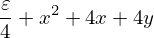

In [7]:
x + 2*y + e/4 + x**2 + 3*x + 2*y

La plupart des fonctions mathématiques sont implémentées symboliquement dans Sympy et il est également possible de les simplifier:

In [8]:
expr = sp.cos(x)**2 + sp.sin(x)**2 + (y**3 + y**2 - y - 1)/(y**2 + 2*y + 1) + sp.exp(-e)
sp.simplify(expr)

Finalement il est possible de faire des substitutions:

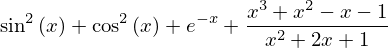

In [9]:
expr.subs(x,y) # substitue x par y
expr.subs({y:x, e:y}) # substitue y par x et e par y

puis par exemple de simplifier l'expression et de tracer son graphe en fonction de `x`:

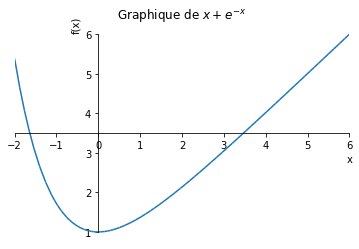

In [11]:
f = sp.simplify(expr.subs({y:x, e:y}))
sp.plot(f,(x,-2,6), title=f"Graphique de ${sp.latex(f)}$")

<!-- dom:FIGURE: [https://python.guillod.org/fig/sympy-plot.png, style="width:90%;max-width:700px;" frac=0.6] -->
<!-- begin figure -->

<p></p>
<img src="https://python.guillod.org/fig/sympy-plot.png" style="width:90%;max-width:700px;">

<!-- end figure -->


**a)**
Lire la documentation de la fonction `solve` et l'utiliser pour calculer les racines d'un polynôme général de degré deux, puis de degré trois.

<!-- --- begin hint in exercise --- -->

**Indication:**
La documentation sur la résolution d'équations algébriques est disponible [ici](http://docs.sympy.org/latest/modules/solvers/solvers.html#algebraic-equations).

<!-- --- end hint in exercise --- -->



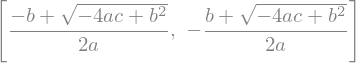

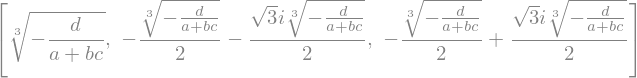

In [90]:
from sympy import *
init_printing(use_unicode=True)
x=Symbol("x",real=True)
a=Symbol("a", real=True)
b=Symbol("b",real=True)
c=Symbol("c",real=True)
d=Symbol("d",real=True)
display(solve(a*x**2+b*x+c,x))
display(solve(a*x**3+b*x**2*+c*x+d,x))


**b)**
Lire la documentation des fonctions `evalf` et `N` pour évaluer l'expression $\frac{\pi^2}{4}$.

<!-- --- begin hint in exercise --- -->

**Indication:**
La documentation sur l'évaluation numérique est disponible [ici](http://docs.sympy.org/latest/modules/evalf.html).

<!-- --- end hint in exercise --- -->



In [91]:
from sympy import *
init_printing(use_unicode=True)
N(pi**2/4)
(pi**2/4).evalf()


**c)**
Déterminer la partie réelle et imaginaire de l'expression:

$$
\bigg(\frac{1+i\sqrt{3}}{1+i}\bigg)^{20} \,.
$$

<!-- --- begin hint in exercise --- -->

**Indication:**
Voir la documentation [ici](https://docs.sympy.org/latest/modules/functions/elementary.html).

<!-- --- end hint in exercise --- -->



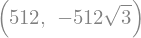

In [92]:
from sympy import *
init_printing(use_unicode=True)
display((re(((1+sqrt(3)*I)/(1+I))**20),im(((1+sqrt(3)*I)/(1+I))**20)))


**d)**
Lire la documentation de la fonction `diff` et calculer la dérivée de $x e^{x^{x^x}}$ par rapport à $x$.

<!-- --- begin hint in exercise --- -->

**Indication:**
La documentation sur les dérivées est disponible [ici](http://docs.sympy.org/latest/tutorial/calculus.html#derivatives).

<!-- --- end hint in exercise --- -->



In [93]:
from sympy import *
init_printing(use_unicode=True)
expr=(x*E**x**x**x)
derivative=diff(expr,x)
display(derivative.subs(x,1))


**e)**
Lire la documentation de la fonction `integrate` et calculer les intégrales suivantes:

$$
\begin{align*}
I_{1} & =\int x^{5}\sin(x)\,\mathrm{d} x \,, &  I_{2} & =\int_{0}^{\infty}\sin(x^{2})\,\mathrm{d} x \,.
\end{align*}
$$

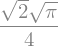

In [94]:
from sympy import *
init_printing(use_unicode=True)
I2=integrate(sin(x**2),(x,0,oo))
I1=Integral(x**5*sin(x),x)
display(I1.doit())
display(I2)


**f)**
Calculer avec Sympy les limites suivantes:

$$
\begin{align*}
L_{1} & =\lim_{x\to0}\frac{\sin(x)}{x}\,, & L_{2} & =\lim_{x\to0}\sin\bigg(\frac{1}{x}\bigg)\,, & L_{3} & =\lim_{x\to\infty}\frac{5x^{2}+3x+2y}{y(x-4)(x-y)}\,.
\end{align*}
$$

In [95]:
from sympy import *
init_printing(use_unicode=True)
x=Symbol("x",real=True)
y=Symbol("y",real=True)
L1=sin(x)/x
L2=sin(1/x)
L3=(5*x**2+3*x+2*y)/(y*(x-4)*(x-y))
display(limit(L1,x,0))
display(limit(L2,x,0))
display(limit(L3,x,oo))


**g)**
Calculer le développement limité de $\tan(x)$ en $x=0$ à l'ordre 10 et le développement asymptotique de $\left(1 + \frac{1}{n}\right)^n$ pour $n\to\infty$ à l'ordre 5.



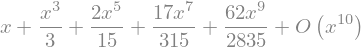

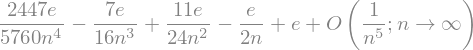

In [96]:
from sympy import *
init_printing(use_unicode=True)
x=Symbol("x",real=True)
n=Symbol("n",real=True)
expr1=tan(x)
display(expr1.series(x,0,10))
expr2=(1+1/n)**n
display(expr2.series(n,oo,5))

In expr2.series(n,oo,5)= $\frac{2447 e}{5760 n^{4}} - \frac{7 e}{16 n^{3}} + \frac{11 e}{24 n^{2}} - \frac{e}{2 n} + e + O\left(\frac{1}{n^{5}}; n\rightarrow \infty\right)$ I do not understand why $\frac{1}{n^5}$ term is omitted. Output in Wolfram Mathematica is: $e-\frac{e}{2 n}+\frac{11 e}{24 n^2}-\frac{7 e}{16 n^3}+\frac{2447 e}{5760 n^4}-\frac{959 e}{2304 n^5}+O\left(\left(\frac{1}{n}\right)^6\right)$

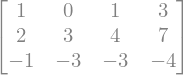

In [83]:
from sympy import *
init_printing(use_unicode=True)
M = Matrix([[1, 0, 1, 3], [2, 3, 4, 7], [-1, -3, -3, -4]])
M


**h)**
Déterminer les valeurs propres de la matrice:

$$
\begin{pmatrix}1 & a & 0\\ 
a & 2 & a\\ 
0 & a & 3
\end{pmatrix}
$$

<!-- --- begin hint in exercise --- -->

**Indication:**
La documentation sur les matrices symboliques est disponible [ici](http://docs.sympy.org/latest/tutorial/matrices.html).

<!-- --- end hint in exercise --- -->



- \left(\lambda - 2\right) \left(2 a^{2} - \lambda^{2} + 4 \lambda - 3\right)


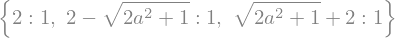

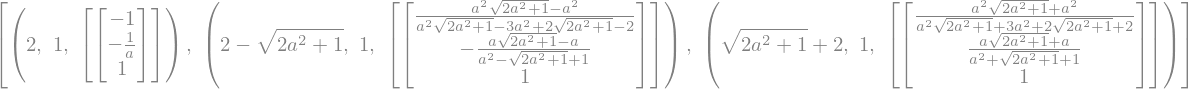

In [98]:
from sympy import *
init_printing(use_unicode=True)
a=Symbol("a",real=True)
M=Matrix([[1,a,0],[a,2,a],[0,a,3]])
p=M.charpoly()
print(latex(factor(p.as_expr())))
display(factor(p.as_expr()))
display(M.eigenvals())
display(M.eigenvects())


<!-- --- end exercise --- -->




<!-- --- begin exercise --- -->

$\left\{ 2 : 1, \  2 - \sqrt{2 a^{2} + 1} : 1, \  \sqrt{2 a^{2} + 1} + 2 : 1\right\}$

# Exercice 4.2: Applications

Le but est d'utiliser Sympy pour résoudre symboliquement différents problèmes mathématiques en calculant le moins de choses possibles à la main.


**a)**
Déterminer le nombre de zéro que contient l'entier $123!$.



Le nombre de zéros à la fin du nombre $123!$ peur être obtenu: $\sum\limits_{k=1}^{\infty } \left\lfloor \frac{123}{5^k}\right\rfloor$


**b)**
Déterminer le rapport entre la hauteur et le rayon d'un cylindre de manière à minimiser son aire à volume fixé.



https://www.youtube.com/watch?v=onjavPruxtM


**c)**
Pour $x,y\in\mathbb{R}$ tels que $xy < 1$, démontrer que:

$$
\arctan(x) + \arctan(y) = \arctan\left(\frac{x+y}{1-xy}\right) \,.
$$

<!-- --- begin hint in exercise --- -->

**Indication:**
Dériver l'équation par rapport à $x$ et justifier.

<!-- --- end hint in exercise --- -->




**d)**
Démontrer la formule suivante due à Gauss:

$$
\frac{\pi}{4} = 12\arctan\left(\frac{1}{38}\right)+20\arctan\left(\frac{1}{57}\right)+7\arctan\left(\frac{1}{239}\right)+24\arctan\left(\frac{1}{268}\right) \,.
$$

Il est impératif d'utiliser Sympy, la démonstration originale de Gauss faisant 25 pages, voir les pages 477 à 502 du deuxième volume de ses œuvres complètes disponible [ici](https://gallica.bnf.fr/ark:/12148/bpt6k99402s).

<!-- --- begin hint in exercise --- -->

**Indication:**
Appliquer la fonction $\tan$ de chaque côté de l'équation puis simplifier. La documentation sur les différentes fonctions de simplifications est disponible [ici](https://docs.sympy.org/latest/tutorial/simplification.html).

<!-- --- end hint in exercise --- -->




**e)**
Déterminer le volume de la région:

$$
\big\{(x,y,z)\in\mathbb{R}^3: x^2+y^2 < z < 2x^2+4xy+6y^2, |y| < 5, |x| < 4\big\} \,.
$$


**f)**
Déterminer l'expression des coefficients de Fourier réels de la fonction $2\pi$-périodique $f$ définie par $f(x)=|\sin(x)|$.





<!-- --- end exercise --- -->




<!-- --- begin exercise --- -->

# Exercice 4.3: Fonction pathologique

Le but est de construire une fonction qui a visuellement l'air d'être régulière, mais qui en fait ne l'est pas.
Soit la fonction $f:\mathbb{R}\to\mathbb{R}$ définie par:

$$
f(x) = \sum_{k=1}^{\infty} \frac{\sin(k^2 x)}{k^5} \,.
$$

Vu que la série converge absolument, la fonction $f$ est bien définie.


**a)**
A l'aide de Sympy calculer la fonction $g:\mathbb{R}\to\mathbb{R}$ définie en gardant les 100 premiers termes de la série:

$$
g(x) = \sum_{k=1}^{100} \frac{\sin(k^2 x)}{k^5} \,,
$$

et représenter la fonction $g$ graphiquement.




**b)**
Estimer à la main l'erreur entre la fonction $f$ et $g$ en valeur absolue.




**c)**
Calculer la dérivée première et la dérivée seconde de $g$ et représenter graphiquement ces deux dérivées. Que pouvez-vous conclure ?




**d)**
Expliquer mathématiquement ce qui se passe.




<!-- --- end exercise --- -->




<!-- --- begin exercise --- -->

# Exercice 4.4: <span style="color:red">!</span> Fonction de Green du laplacien

Le but final de cet exercice est de calculer entièrement automatiquement la fonction de Green du laplacien dans $\mathbb{R}^3$, *i.e.* la solution satisfaisant

$$
\Delta G(\boldsymbol{x}) = \delta(\boldsymbol{x}) \,,
$$

dans $\mathbb{R}^3$ où $\delta(\boldsymbol{x})$ est la distribution de Dirac.

Pour cela, nous introduisons les coordonnées sphériques $\boldsymbol{x}^\prime = (r,\theta,\varphi)$ avec $r>0$, $0 \leq \theta \leq \pi$, et $0 \leq \varphi < 2\pi$ caractérisées par:

$$
\begin{align*}
x_1 & =r\cos\varphi\sin\theta\\ 
x_2 & =r\sin\varphi\sin\theta\\ 
x_3 & =r\cos\theta \,.
\end{align*}
$$

**a)**
Définir une fonction `to_spherical(expr)` permettant de convertir en coordonnées sphériques une expression donnée en coordonnées cartésiennes.




**b)**
Définir une fonction `to_cartesian(expr)` permettant de convertir en coordonnées cartésiennes une expression donnée en coordonnées sphériques.




**c)**
Calculer les facteurs d'échelle des coordonnées sphériques:

$$
h_i = \left\Vert \frac{\partial\boldsymbol{x}}{\partial x^\prime_i} \right\Vert.
$$


**d)**
Définir une fonction `gradient(f)` permettant de calculer le gradient d'une fonction $f:\mathbb{R}^3\to\mathbb{R}$ en coordonnées sphériques:

$$
\boldsymbol{\nabla}f = \left( \frac{1}{h_i}\frac{\partial f}{\partial x^\prime_i} \right)_{i=1}^3\,.
$$


**e)**
Faire de même pour définir le laplacien en coordonnées sphériques:

$$
\Delta f = \sum_{i=1}^3 \frac{1}{J} \frac{\partial}{\partial x^\prime_i} \left( \frac{J}{h_i^2} \frac{\partial f}{\partial x^\prime_i} \right) \quad \text{où} \quad J = \prod_{i=1}^3 h_i \,.
$$


**f)**
Trouver les solutions radiales (*i.e.* ne dépendant que de la variable $r$) de l'équation $\Delta G = 0$ dans $\mathbb{R}^3\setminus\{\boldsymbol{0}\}$.

<!-- --- begin hint in exercise --- -->

**Indication:**
Regarder la documentation de la fonction `dsolve` pour résoudre une équation différentielle.

<!-- --- end hint in exercise --- -->




**g)**
Déterminer les équations que doivent satisfaire les constantes d'intégration pour que la solution précédente satisfasse en coordonnées cartésiennes:

$$
\lim_{|\boldsymbol{x}|\to\infty} G(\boldsymbol{x}) = 0 \quad \text{et} \quad \Delta G(\boldsymbol{x}) = \delta(\boldsymbol{x}) \,.
$$

<!-- --- begin hint in exercise --- -->

**Indication:**
Il faut transformer les deux conditions en coordonnées sphériques.
La première condition s'exprime en coordonnées sphériques par:

$$
\lim_{r\to\infty} G(r) = 0 \,,
$$

et la seconde est équivalente à:

$$
\lim_{r \to 0} \int_{0}^{\pi} \int_{0}^{2\pi} \big( \boldsymbol{\nabla} G(r) \boldsymbol{\cdot} \boldsymbol{e}_r \big) \, J(r,\theta,\varphi) \, \mathrm{d}\varphi \mathrm{d}\theta = 1\,.
$$

<!-- --- end hint in exercise --- -->




**h)**
Résoudre les équations sur les constantes d'intégrations et substituer dans la solution radial de $\Delta G = 0$ pour obtenir l'expression de la fonction de Green du laplacien en coordonnées sphériques. Finalement déterminer la fonction de Green $G$ du laplacien dans $\mathbb{R}^3$ en coordonnées cartésiennes.




**i)**
<span style="color:red">!!</span>
Soit $g:\mathbb{R}^3 \to \mathbb{R}$ une fonction lisse à support compact invariante par rotations selon l'axe vertical. Déterminer le comportement asymptotique à grandes distances de la solution de l'équation:

$$
\Delta f(\boldsymbol{x}) = g(\boldsymbol{x}) \,
$$

jusqu'à l'ordre deux, *i.e.* les termes décroissant comme $|\boldsymbol{x}|^{-1}$ et comme $|\boldsymbol{x}|^{-2}$.

<!-- --- begin hint in exercise --- -->

**Indication:**
La solution est donnée par la formule de Green:

$$
f(\boldsymbol{x}) = \int_{\mathbb{R}^3} G(\boldsymbol{x}-\boldsymbol{x}_0) g(\boldsymbol{x}_0) \, \mathrm{d}^3\boldsymbol{x}_0 = \int_{B_R} G(\boldsymbol{x}-\boldsymbol{x}_0) g(\boldsymbol{x}_0) \, \mathrm{d}^3\boldsymbol{x}_0 \,,
$$

où $R$ est choisi de sorte à ce que le support de $g$ soit contenu dans $B_R$.
Pour calculer le développement asymptotique de cette intégrale, la première étape est de convertir $G(\boldsymbol{x}-\boldsymbol{x}_0)$ en coordonnées sphériques pour $\boldsymbol{x}$ et $\boldsymbol{x}_0$. Vu que $g$ est invariante par rotations selon l'axe vertical, alors en coordonnées sphérique $g$ est indépendante de $\varphi$ et est donné par $g(r,\theta)$.
La seconde étape est de transformer l'intégrale en coordonnées sphériques avec une intégrale triple sur $r_0$, $\theta_0$ et $\varphi_0$.
La troisième étape est de calculer le développement asymptotique de l'intégrant lorsque $r\to\infty$, jusqu'à l'ordre deux. Finalement, vu que $r_0$, $\theta_0$ et $\varphi_0$ sont bornés, alors l'intégration commute avec le développement asymptotique et le résultat final est donné par l'intégration individuelle des deux termes du développement asymptotique.

<!-- --- end hint in exercise --- -->




<!-- --- end exercise --- -->